<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Datos Masivos II · PRÁCTICA 4</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Recomendar pares que nadie ha probado</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

**Qué hace.** Toma el modelo híbrido de `BindingDB_Recomendador.ipynb` y lo pone a hacer lo que un recomendador hace de verdad: proponer **pares proteína–molécula que nadie ha medido todavía**.

**Por qué hace falta un notebook aparte.** El primero evalúa sobre pares medidos, que son los únicos con verdad conocida. Aquí no hay verdad que comparar, así que el problema cambia: hay que **validar de otra manera** y hay que **declarar cuándo no creerle al modelo**.

**Tiempo.** ~9 min con la caché de huellas construida.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Qué cambia al recomendar lo no medido</span></div>

Recomendar pares no probados **es el objetivo** de un sistema de recomendación; lo demás era andamio para comprobar que el modelo ordena mejor que el azar. Pero al pasar de evaluar a recomendar cambian tres cosas, y conviene fijarlas antes de ver un solo número.

### 1. La tasa base se derrumba

En los pares **medidos**, el 62 % son activos, porque un químico prueba lo que cree que va a funcionar. En pares **no medidos**, la proporción real de aciertos es de órdenes de magnitud menor: el espacio es inmenso y casi nada se une a casi nada.

> Por eso la `precision@10` del primer notebook **no se transfiere** a un catálogo nuevo. Lo que sí se transfiere es la capacidad **relativa** de ordenar: el enriquecimiento. Prometer precisión absoluta sobre pares nuevos sería deshonesto.

### 2. No hay verdad, pero sí se puede validar

Parece que sin verdad no hay evaluación posible. Hay dos salidas, y se usan las dos:

| Validación | Cómo | Qué demuestra |
|---|---|---|
| **retrospectiva** | entrenar con lo publicado hasta 2022 y puntuar lo que se midió **después** | que el modelo acierta sobre pares que estaban sin medir cuando se entrenó |
| **por dilución** | mezclar los candidatos con verdad entre miles de moléculas sin medir y ver si los conocidos siguen subiendo | que el orden sobrevive cuando el 99 % de los candidatos es desconocido |

La primera es exactamente la partición temporal del primer notebook, vista desde el otro lado: **esos pares de prueba estaban sin medir en el momento del entrenamiento**. La segunda es nueva y es la que simula el uso real.

### 3. Hay que declarar el dominio de aplicabilidad

Una predicción solo es creíble si la molécula consultada cae en la región del espacio químico que el modelo vio. El nombre formal es **dominio de aplicabilidad**, y aquí se operacionaliza con el Tanimoto a la molécula conocida más cercana: por debajo de un umbral, la recomendación es una extrapolación y se marca como tal en lugar de dejarla pasar.

### Lo que este notebook puede y no puede afirmar

**Sí:** que el modelo ordena candidatos mejor que el azar, que mantiene ese orden cuando se diluye entre desconocidos, y qué recomendaciones concretas propone con qué nivel de respaldo.

**No:** que un par recomendado se una de verdad. Eso solo lo dice un experimento.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Configuración</span></div>

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
from sklearn.metrics import roc_auc_score

from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Draw
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 190)

PROC    = Path("data/processed")
IN_INT  = PROC / "rec_interacciones.parquet"
IN_LIG  = PROC / "rec_ligandos.parquet"
IN_TGT  = PROC / "rec_targets.parquet"
OUT_REC = PROC / "recomendaciones_pares_nuevos.csv"
OUT_RES = PROC / "rec_pares_nuevos.json"
FIG_DIR = Path("figs/pares_nuevos"); FIG_DIR.mkdir(parents=True, exist_ok=True)

# ========================= PARÁMETROS =========================
# Los seis primeros son los mismos del notebook principal y no deben cambiarse aquí:
# el modelo es el de allá, no uno nuevo.
UMBRAL     = 6.0
FP_RADIO, FP_BITS = 2, 2048
K_MER      = 3
K_VEC_LIG, MIN_TANIMOTO = 25, 0.15
K_VEC_PROT, MIN_SOLAPE  = 30, 5
N_PROT_VEC, CAP_VECINO  = 10, 300
BETA, EPS  = 0.5, 0.5
LAM, GAM   = 2.0, 3.0      # pesos elegidos en la validación interna del notebook principal

# Propios de este notebook
TEST_FRAC  = 0.20          # para la validación retrospectiva
MAX_TEST_POR_PROT = 300
TOP_K      = 10
MIN_TEST_LIG = 10
CAP_PROPIO = 1500          # tope de moléculas propias usadas al puntuar un catálogo grande
N_POOL     = 30_000        # tamaño del catálogo de moléculas nunca medidas
N_PROT_DEMO = 8            # proteínas para las que se generan recomendaciones
DILUCION   = 20            # desconocidas por cada candidato con verdad, en la prueba de dilución
TANI_MIN_CONFIABLE = 0.30  # frontera del dominio de aplicabilidad
SEMILLA    = 0
rng = np.random.default_rng(SEMILLA)

# ========================= ESTILO =========================
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
CAT = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
GRIS = "#8a8984"
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "azul", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.linewidth": .8, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": .6, "axes.axisbelow": True,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False, "axes.prop_cycle": cycler(color=CAT)})

def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight"); plt.show()
def pct(a, b): return 100 * a / b if b else float("nan")
def miles(ax, eje="y"):
    getattr(ax, f"{eje}axis").set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))

RES = {}
print(f"Modelo del notebook principal: λ = {LAM:g} | γ = {GAM:g} | ε = {EPS:g}")
print(f"Catálogo de moléculas nunca medidas: {N_POOL:,} | proteínas con recomendación: {N_PROT_DEMO}")

Modelo del notebook principal: λ = 2 | γ = 3 | ε = 0.5
Catálogo de moléculas nunca medidas: 30,000 | proteínas con recomendación: 8


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Datos y representación</span></div>

In [2]:
t0 = time.time()
I = pd.read_parquet(IN_INT)
L = pd.read_parquet(IN_LIG)
T = pd.read_parquet(IN_TGT)
I = I[~I["conflicto_cotas"]].reset_index(drop=True)
L = L[L["lig_id"].isin(set(I["lig_id"]))].reset_index(drop=True)
T = T[T["target_id"].isin(set(I["target_id"]))].reset_index(drop=True)

# --- huellas (se reusa la caché del notebook principal) ---
gen = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIO, fpSize=FP_BITS)
CACHE_FP = PROC / f"fp_morgan_r{FP_RADIO}_{FP_BITS}.npz"
CACHE_ID = CACHE_FP.with_suffix(".parquet")
meta = pd.read_parquet(CACHE_ID) if (CACHE_FP.exists() and CACHE_ID.exists()) else None
vale = (meta is not None and len(meta) == len(L)
        and np.array_equal(meta["lig_id"].to_numpy(), L["lig_id"].to_numpy()))
if vale:
    z = np.load(CACHE_FP)
    FP = sp.csr_matrix((z["data"], z["indices"], z["indptr"]), shape=tuple(z["shape"]))
    validos = np.nonzero(meta["_valido"].to_numpy())[0]
    print(f"Huellas leídas de {CACHE_FP.name}")
else:
    filas, cols, validos = [], [], []
    for j, smi in enumerate(L["smiles"].to_numpy()):
        m_ = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
        if m_ is None: continue
        b_ = np.nonzero(gen.GetFingerprintAsNumPy(m_))[0]
        filas.append(np.full(b_.size, len(validos))); cols.append(b_); validos.append(j)
    validos = np.asarray(validos)
    FP = sp.csr_matrix((np.ones(sum(len(c) for c in cols), np.float32),
                        (np.concatenate(filas), np.concatenate(cols))),
                       shape=(len(validos), FP_BITS))
    meta = pd.DataFrame({"lig_id": L["lig_id"].to_numpy(), "_valido": False})
    meta.loc[validos, "_valido"] = True
    sp.save_npz(CACHE_FP, FP); meta.to_parquet(CACHE_ID, index=False)
    print("Huellas calculadas y cacheadas")
L = L.iloc[validos].reset_index(drop=True)
I = I[I["lig_id"].isin(set(L["lig_id"]))].reset_index(drop=True)

# --- 3-meros de la secuencia ---
AA = "ACDEFGHIKLMNPQRSTVWY"; IX_AA = {a: i for i, a in enumerate(AA)}
N_KMER = 20 ** K_MER
def vector_kmeros(seq):
    v = np.zeros(N_KMER, np.float32)
    if not isinstance(seq, str): return v
    s = seq.upper()
    for p in range(len(s) - K_MER + 1):
        idx, ok = 0, True
        for ch in s[p:p+K_MER]:
            j = IX_AA.get(ch)
            if j is None: ok = False; break
            idx = idx*20 + j
        if ok: v[idx] += 1
    n = v.sum()
    return v/n if n else v
KM = np.vstack([vector_kmeros(s) for s in T["secuencia"].to_numpy()])
nrm = np.linalg.norm(KM, axis=1, keepdims=True); nrm[nrm == 0] = 1
KM_N = (KM/nrm).astype(np.float32)
S_SEQ = (KM_N @ KM_N.T).astype(np.float32); np.fill_diagonal(S_SEQ, 0.0)

TGT_IX = pd.Series(np.arange(len(T)), index=T["target_id"])
LIG_IX = pd.Series(np.arange(len(L)), index=L["lig_id"])
I["_u"] = TGT_IX.reindex(I["target_id"]).to_numpy()
I["_i"] = LIG_IX.reindex(I["lig_id"]).to_numpy()
I = I[I["_u"].notna() & I["_i"].notna()].copy()
I[["_u", "_i"]] = I[["_u", "_i"]].astype(int)
n_prot, n_lig = len(T), len(L)
nom_lig = L.set_index("lig_id")["nombre"]; nom_tgt = T.set_index("target_id")["nombre"]
smi_lig = L.set_index("lig_id")["smiles"]

print(f"Pares medidos {len(I):,} | proteínas {n_prot:,} | moléculas {n_lig:,}  "
      f"[{time.time()-t0:.0f}s]")
CELDAS = n_prot * n_lig
print(f"Celdas de la matriz: {CELDAS:,}  |  medidas: {100*len(I)/CELDAS:.4f}%  |  "
      f"SIN MEDIR: {CELDAS-len(I):,}")
RES["celdas_totales"] = int(CELDAS); RES["pares_medidos"] = int(len(I))

Huellas leídas de fp_morgan_r2_2048.npz
Pares medidos 1,248,252 | proteínas 3,444 | moléculas 830,999  [9s]
Celdas de la matriz: 2,861,960,556  |  medidas: 0.0436%  |  SIN MEDIR: 2,860,712,304


**Lectura.** El número que define este notebook es el último: hay **más de 2,800 millones de pares proteína–molécula sin medir** contra 1.25 millones medidos. El recomendador existe precisamente porque nadie va a probar ese espacio al azar, y el 99.96 % de él no tiene ninguna etiqueta que permita verificar nada.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. El modelo, como objeto que se ajusta y se usa</span></div>

Para recomendar sobre pares arbitrarios hace falta separar lo que el primer notebook tenía entremezclado: **ajustar** el modelo con los datos disponibles y **puntuar** cualquier par que se le pida, medido o no.

`ajustar(base)` guarda todo lo que el modelo necesita recordar; `puntuar(M, proteínas, moléculas)` devuelve el `pIC50` estimado de cualquier lista de pares, junto con el Tanimoto de respaldo que después define el dominio de aplicabilidad. Es la misma fórmula del notebook principal, con los mismos pesos:

$$\hat s(u,i) = \frac{\sum_j T(i,j) r(u,j) \;+\; \lambda \sum_v \sum_j \text{sim}(u,v) T(i,j)\big(r(v,j) - \mu_v\big) \;+\; \gamma\,\text{pop}(i) \;+\; \varepsilon \mu_u}{\text{den}_1 + \lambda\,\text{den}_2 + \gamma\,[\exists\,\text{pop}] + \varepsilon}$$

In [3]:
POP_BITS = np.asarray(FP.getnnz(axis=1), np.float32)
TOPE_CELDAS = 20_000_000

def tanimoto(ia, ib):
    inter = np.asarray((FP[ia] @ FP[ib].T).todense(), np.float32)
    union = POP_BITS[ia][:, None] + POP_BITS[ib][None, :] - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)

def knn(idx_q, idx_ref, y_ref, w_fila=None):
    """Suma ponderada por Tanimoto de los K_VEC_LIG vecinos. Devuelve (num, den, tanimoto_max)."""
    n = len(idx_q)
    num = np.zeros(n); den = np.zeros(n); smax = np.zeros(n, np.float32)
    if len(idx_ref) == 0: return num, den, smax
    paso = max(1, int(TOPE_CELDAS // len(idx_ref)))
    for a in range(0, n, paso):
        b = min(a+paso, n); sub = idx_q[a:b]
        Tm = tanimoto(sub, idx_ref)
        Tm[sub[:, None] == idx_ref[None, :]] = 0.0
        Tm[Tm < MIN_TANIMOTO] = 0.0
        kk = min(K_VEC_LIG, Tm.shape[1])
        if kk < Tm.shape[1]:
            c_ = np.partition(Tm, -kk, 1)[:, -kk][:, None]
            Tm = np.where(Tm >= c_, Tm, 0.0)
        smax[a:b] = Tm.max(1)
        Wm = Tm if w_fila is None else Tm * w_fila[None, :]
        num[a:b] = Wm @ y_ref; den[a:b] = Wm.sum(1)
    return num, den, smax

def calificacion(df):
    """pIC50 del par; si solo hay cotas, un punto junto al umbral según 'activo'."""
    y = df["pIC50"].to_numpy(dtype="float32", na_value=np.nan)
    rel = np.where(df["activo"].to_numpy() == 1, UMBRAL+.5, UMBRAL-.5).astype(np.float32)
    return np.where(np.isnan(y), rel, y)

def ajustar(base):
    """Memoriza del conjunto `base` todo lo que hace falta para puntuar cualquier par."""
    yb = calificacion(base); mub = float(yb.mean())
    mu_u = (pd.Series(yb).groupby(base["_u"].to_numpy()).mean()
              .reindex(range(n_prot)).fillna(mub).to_numpy(np.float32))
    # similitud entre proteínas: co-ocurrencia mezclada con secuencia
    Bb = sp.csr_matrix((np.ones(len(base), np.float32), (base["_u"], base["_i"])),
                       shape=(n_prot, n_lig)); Bb.data[:] = 1.0
    nb_ = np.sqrt(np.asarray(Bb.multiply(Bb).sum(1))).ravel(); nb_[nb_ == 0] = 1
    Bn = sp.diags(1/nb_) @ Bb
    S_col = np.asarray((Bn @ Bn.T).todense(), np.float32)
    Ov = np.asarray((Bb @ Bb.T).todense(), np.int32)
    S_col[Ov < MIN_SOLAPE] = 0.0; np.fill_diagonal(S_col, 0.0)
    if K_VEC_PROT < n_prot:
        c_ = np.partition(S_col, -K_VEC_PROT, 1)[:, -K_VEC_PROT][:, None]
        S_col = np.where(S_col >= c_, S_col, 0.0)
    off = ~np.eye(n_prot, dtype=bool)
    Ss = np.clip(S_SEQ - S_SEQ[off].mean(), 0, None); Ss /= (Ss.max() or 1)
    S = (BETA*S_col + (1-BETA)*Ss).astype(np.float32); np.fill_diagonal(S, 0.0)
    if N_PROT_VEC < n_prot:
        c_ = np.partition(S, -N_PROT_VEC, 1)[:, -N_PROT_VEC][:, None]
        S = np.where(S >= c_, S, 0.0)
    f_ = S.sum(1, keepdims=True); S_prot = S / np.where(f_ == 0, 1, f_)

    por_prot = {}
    for p, g in base.groupby("_u", observed=True):
        por_prot[int(p)] = (g["_i"].to_numpy(), calificacion(g))
    gl = pd.Series(yb).groupby(base["_i"].to_numpy()).agg(["sum", "size"])
    return dict(mu_u=mu_u, mu=mub, S_prot=S_prot, por_prot=por_prot,
                pop_sum=gl["sum"], pop_n=gl["size"],
                medidos=set(zip(base["_u"].to_numpy(), base["_i"].to_numpy())))

def puntuar(M, u_arr, i_arr, cap_propio=None, verbose=False):
    """pIC50 estimado de cada par (u, i). Devuelve (score, tanimoto_max, n_fuentes).

    No requiere que el par esté medido: solo necesita la huella de la molécula. Por eso
    sirve igual para evaluar sobre pares con verdad que para recomendar sobre pares nuevos.
    `cap_propio` limita cuántas moléculas de la propia proteína se usan, por costo.
    """
    u_arr = np.asarray(u_arr); i_arr = np.asarray(i_arr); n = len(u_arr)
    n1 = np.zeros(n); d1 = np.zeros(n); n2 = np.zeros(n); d2 = np.zeros(n)
    smax = np.zeros(n, np.float32)
    t0 = time.time()
    agrup = pd.DataFrame({"u": u_arr, "i": i_arr, "pos": np.arange(n)}).groupby("u", sort=False)
    for k_, (p, g) in enumerate(agrup):
        p = int(p); pos = g["pos"].to_numpy(); idx_q = g["i"].to_numpy()
        # fuente 1: moléculas parecidas que ESTA proteína ya midió
        propio = M["por_prot"].get(p)
        if propio is not None and len(propio[0]):
            ir, yr = propio
            if cap_propio and len(ir) > cap_propio:
                sel = rng.choice(len(ir), cap_propio, replace=False)
                ir, yr = ir[sel], yr[sel]
            a_, b_, s_ = knn(idx_q, ir, yr)
            n1[pos], d1[pos], smax[pos] = a_, b_, s_
        # fuente 2: proteínas vecinas sobre moléculas parecidas, centradas por su media
        vs = np.nonzero(M["S_prot"][p])[0]
        if vs.size:
            iv, yv, wv = [], [], []
            for v in vs:
                pv = M["por_prot"].get(int(v))
                if pv is None or not len(pv[0]): continue
                iu, yu = pv
                if len(iu) > CAP_VECINO:
                    sel = rng.choice(len(iu), CAP_VECINO, replace=False)
                    iu, yu = iu[sel], yu[sel]
                iv.append(iu); yv.append(yu - M["mu_u"][v])
                wv.append(np.full(len(iu), M["S_prot"][p, v], np.float32))
            if iv:
                a_, b_, _ = knn(idx_q, np.concatenate(iv), np.concatenate(yv),
                                w_fila=np.concatenate(wv))
                n2[pos], d2[pos] = a_, b_
        if verbose:
            print(f"  proteína {k_+1}: {len(idx_q):,} candidatos  [{time.time()-t0:.0f}s]",
                  flush=True)
    s_l = M["pop_sum"].reindex(i_arr).to_numpy(); c_l = M["pop_n"].reindex(i_arr).to_numpy()
    hay = np.nan_to_num(c_l) > 0
    pop = np.where(hay, (np.nan_to_num(s_l) + 2*M["mu"])/(np.nan_to_num(c_l) + 2), M["mu"])
    mu_u = M["mu_u"][u_arr]
    num = n1 + LAM*(n2 + d2*mu_u) + GAM*hay*pop + EPS*mu_u
    den = d1 + LAM*d2 + GAM*hay + EPS
    # n_fuentes: cuántas de las tres evidencias respaldan la puntuación
    nfu = ((d1 > 0).astype(np.int8) + (d2 > 0).astype(np.int8) + hay.astype(np.int8))
    return num/den, smax, nfu

print("Listo: ajustar(base) y puntuar(M, proteínas, moléculas)")

Listo: ajustar(base) y puntuar(M, proteínas, moléculas)


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Validación retrospectiva</span></div>

Se entrena con lo publicado hasta un año de corte y se puntúan los pares medidos **después**. Esos pares estaban sin medir cuando el modelo se ajustó, así que esto no es una simulación: es exactamente la situación de recomendar algo no probado, con la ventaja de que el tiempo ya reveló la respuesta.

In [4]:
anio = I["anio_min"].astype(float)
CORTE = np.nanquantile(anio, 1 - TEST_FRAC)
m_tr = ((anio <= CORTE).fillna(False) | anio.isna()).to_numpy(bool)
pasado = I[m_tr].reset_index(drop=True)
_f = I[~m_tr].sample(frac=1, random_state=SEMILLA)
futuro = (_f[_f.groupby("target_id", observed=True).cumcount() < MAX_TEST_POR_PROT]
          .reset_index(drop=True))
print(f"Entreno con lo publicado hasta {CORTE:.0f}: {len(pasado):,} pares")
print(f"Puntúo lo medido después: {len(futuro):,} pares, de los cuales "
      f"{100*(~futuro['lig_id'].isin(set(pasado['lig_id']))).mean():.1f}% traen una molécula nueva")

t0 = time.time()
MOD = ajustar(pasado)
sc, tani, nfu = puntuar(MOD, futuro["_u"].to_numpy(), futuro["_i"].to_numpy())
futuro["score"] = sc; futuro["tanimoto_max"] = tani; futuro["n_fuentes"] = nfu
print(f"Ajuste y puntuación en {time.time()-t0:.0f}s")

def evaluar(df, score, nombre, k=TOP_K):
    """Métricas de ranking por proteína."""
    d = df.assign(_sc=np.asarray(score, float)).sample(frac=1, random_state=SEMILLA)
    mn = d["_sc"].min(); d["_sc"] = d["_sc"].fillna(mn-1 if np.isfinite(mn) else 0.0)
    filas = []
    for pid, g in d.groupby("target_id", observed=True):
        if len(g) < MIN_TEST_LIG: continue
        ya = g["activo"].to_numpy()
        if ya.sum() == 0 or ya.sum() == len(ya): continue
        gs = g.sort_values("_sc", ascending=False)
        y = gs["activo"].to_numpy(); kk = min(k, len(y))
        prev = y.mean(); prec = y[:kk].mean()
        disc = 1/np.log2(np.arange(2, kk+2))
        idcg = (np.sort(y)[::-1][:kk]*disc).sum()
        filas.append(dict(target_id=pid, n=len(y), prevalencia=prev,
                          **{f"precision@{k}": prec,
                             f"ndcg@{k}": (y[:kk]*disc).sum()/idcg if idcg > 0 else np.nan},
                          enriquecimiento=prec/prev if prev > 0 else np.nan,
                          techo=(min(kk, int(ya.sum()))/kk)/prev if prev > 0 else np.nan,
                          auc=roc_auc_score(y, gs["_sc"].to_numpy())))
    r = pd.DataFrame(filas); r.insert(0, "modelo", nombre); return r

det = pd.concat([evaluar(futuro, rng.random(len(futuro)), "azar"),
                 evaluar(futuro, futuro["score"], "híbrido")], ignore_index=True)
MET = [f"precision@{TOP_K}", f"ndcg@{TOP_K}", "enriquecimiento", "auc"]
tabla = det.groupby("modelo", observed=True)[MET].mean().reindex(["azar", "híbrido"])
TECHO = float(det["techo"].mean()); PREV = float(det["prevalencia"].mean())
tabla["% del margen"] = 100*(tabla["enriquecimiento"]-1)/(TECHO-1)
print(f"\nProteínas evaluadas {det['target_id'].nunique():,} | prevalencia {PREV:.3f} "
      f"| techo {TECHO:.3f}×")
display(tabla.style.format({f"precision@{TOP_K}": "{:.4f}", f"ndcg@{TOP_K}": "{:.4f}",
                            "enriquecimiento": "{:.3f}×", "auc": "{:.4f}",
                            "% del margen": "{:.1f}%"}))
RES["retrospectiva"] = json.loads(tabla.to_json(orient="index"))
RES["retrospectiva"]["techo"] = round(TECHO, 4)

Entreno con lo publicado hasta 2022: 1,040,255 pares
Puntúo lo medido después: 107,399 pares, de los cuales 97.3% traen una molécula nueva
Ajuste y puntuación en 23s

Proteínas evaluadas 668 | prevalencia 0.632 | techo 2.320×


,precision@10,ndcg@10,enriquecimiento,auc,% del margen
modelo,,,,,
azar,0.6262,0.6465,0.995×,0.4928,-0.4%
híbrido,0.7045,0.7413,1.214×,0.6181,16.2%


**Lectura.** El modelo ordena pares que estaban sin medir mejor que el azar, y eso es lo que da licencia para usarlo sobre pares que **siguen** sin medir. Pero fíjese en la `precision@10`: parece altísima, y no lo es tanto. Es alta **porque la prevalencia de activos entre los pares medidos es del 63 %** — alguien ya había decidido que valía la pena probarlos. Lo que hay que mirar es el enriquecimiento y el porcentaje del margen recorrido.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Prueba de dilución</span></div>

Aquí está la diferencia real con el notebook principal. Hasta ahora el modelo elegía entre candidatos que **todos** habían sido medidos. En el uso real debe elegir entre miles de moléculas de las que no se sabe nada.

La prueba: a los candidatos con verdad de cada proteína se les añaden `DILUCION` moléculas **nunca medidas contra esa proteína** por cada uno, se ordena la mezcla y se observa qué pasa con los activos conocidos. Si siguen subiendo al top, el orden sobrevive a la dilución; si los desconocidos los desplazan, el modelo no distingue y la recomendación sería ruido.

In [5]:
eval_ok = (det[det["modelo"] == "híbrido"].dropna(subset=["enriquecimiento"])
           .sort_values("n", ascending=False))
PROTS = eval_ok["target_id"].head(N_PROT_DEMO).tolist()
print("Proteínas:", ", ".join(f"{p} ({str(nom_tgt.get(p,''))[:28]})" for p in PROTS))

medidos_por_prot = {int(u): set(g) for u, g in I.groupby("_u")["_i"]}
filas, ejemplos = [], {}
t0 = time.time()
for pid in PROTS:
    u = int(TGT_IX[pid])
    con_verdad = futuro[futuro["target_id"] == pid]
    if len(con_verdad) < MIN_TEST_LIG: continue
    ya = medidos_por_prot.get(u, set())
    libres = np.setdiff1d(np.arange(n_lig), np.array(sorted(ya), dtype=int))
    n_dil = min(DILUCION*len(con_verdad), len(libres))
    dil = rng.choice(libres, n_dil, replace=False)

    idx = np.r_[con_verdad["_i"].to_numpy(), dil]
    s_, t_, _ = puntuar(MOD, np.full(len(idx), u), idx, cap_propio=CAP_PROPIO)
    act = np.r_[con_verdad["activo"].to_numpy(), np.full(len(dil), -1)]   # -1 = desconocido
    o = np.argsort(-s_)
    top = act[o[:TOP_K]]
    filas.append({"proteína": pid, "con verdad": len(con_verdad), "diluyentes": len(dil),
                  "activos conocidos en el top-10": int((top == 1).sum()),
                  "inactivos conocidos en el top-10": int((top == 0).sum()),
                  "desconocidos en el top-10": int((top == -1).sum()),
                  "prevalencia entre los conocidos": con_verdad["activo"].mean(),
                  "% con verdad en la mezcla": 100*len(con_verdad)/len(idx)})
    ejemplos[pid] = dict(idx=idx[o], score=s_[o], tani=t_[o], act=act[o])
dil_df = pd.DataFrame(filas)
print(f"\nDilución calculada en {time.time()-t0:.0f}s\n")
display(dil_df.style.format({"con verdad": "{:,}", "diluyentes": "{:,}",
    "prevalencia entre los conocidos": "{:.2f}", "% con verdad en la mezcla": "{:.1f}%"})
    .hide(axis="index"))

esp = dil_df["% con verdad en la mezcla"].mean()/100*TOP_K
obs = (dil_df["activos conocidos en el top-10"] + dil_df["inactivos conocidos en el top-10"]).mean()
print(f"De los 10 primeros, por azar se esperarían {esp:.2f} candidatos con verdad; "
      f"se observan {obs:.2f}.")
print(f">>> El modelo concentra los pares ya medidos en el top {obs/esp:.1f} veces más "
      "de lo que daría el azar.")
RES["dilucion"] = json.loads(dil_df.to_json(orient="records"))
RES["dilucion_concentracion"] = round(float(obs/esp), 2)

Proteínas: Q9Y5Y9 (Sodium channel protein type ), C9J9Y7 (Potassium sodium-activated c), Q9UGN5 (Poly [ADP-ribose] polymerase), Q9UKU6 (Thyrotropin-releasing hormon), Q8N884 (Cyclic GMP-AMP synthase), Q8IVH8 (Mitogen-activated protein ki), Q9UDY8 (Mucosa-associated lymphoid t), Q9UBN7 (Protein deacetylase HDAC6)

Dilución calculada en 7s



proteína,con verdad,diluyentes,activos conocidos en el top-10,inactivos conocidos en el top-10,desconocidos en el top-10,prevalencia entre los conocidos,% con verdad en la mezcla
Q9Y5Y9,300,"6,000",9,1,0,0.80,4.8%
C9J9Y7,300,"6,000",0,0,10,0.88,4.8%
Q9UGN5,300,"6,000",9,0,1,0.39,4.8%
Q9UKU6,300,"6,000",0,0,10,0.99,4.8%
Q8N884,300,"6,000",0,0,10,0.91,4.8%
Q8IVH8,300,"6,000",0,0,10,0.90,4.8%
Q9UDY8,300,"6,000",10,0,0,0.59,4.8%
Q9UBN7,300,"6,000",8,0,2,0.87,4.8%


De los 10 primeros, por azar se esperarían 0.48 candidatos con verdad; se observan 4.62.
>>> El modelo concentra los pares ya medidos en el top 9.7 veces más de lo que daría el azar.


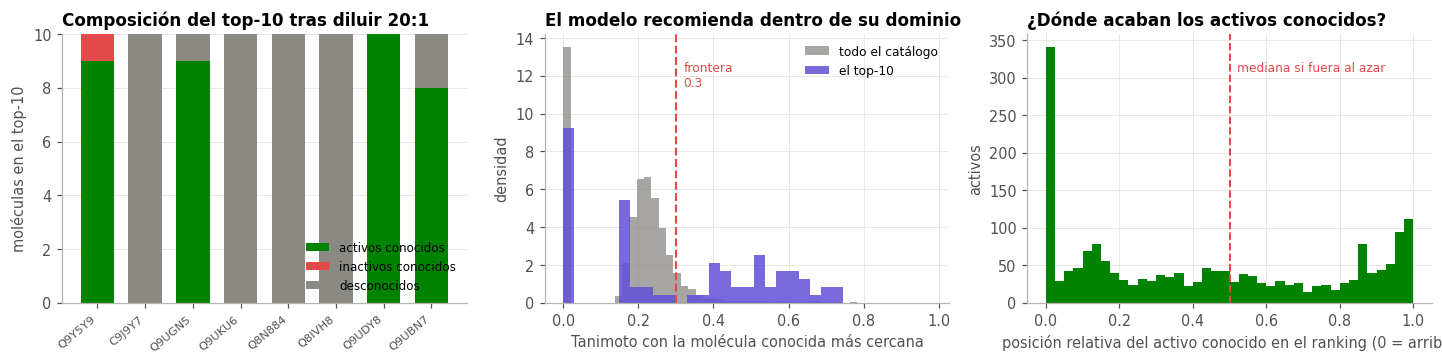

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.4))

ax = axes[0]
comp = dil_df[["activos conocidos en el top-10", "inactivos conocidos en el top-10",
               "desconocidos en el top-10"]]
abajo = np.zeros(len(dil_df))
for c_, col in zip(comp.columns, [VERDE, ROJO, GRIS]):
    ax.bar(range(len(dil_df)), comp[c_], bottom=abajo, color=col,
           label=c_.replace(" en el top-10", ""), width=.7)
    abajo += comp[c_].to_numpy()
ax.set_xticks(range(len(dil_df)))
ax.set_xticklabels(dil_df["proteína"], rotation=40, ha="right", fontsize=7.5)
ax.set_ylabel(f"moléculas en el top-{TOP_K}"); ax.legend(fontsize=7.8, loc="lower right")
ax.set_title(f"Composición del top-{TOP_K} tras diluir {DILUCION}:1")

ax = axes[1]
tv = np.concatenate([e["tani"][:TOP_K] for e in ejemplos.values()])
tr_ = np.concatenate([e["tani"] for e in ejemplos.values()])
ax.hist(tr_, bins=50, color=GRIS, alpha=.75, density=True, label="todo el catálogo")
ax.hist(tv, bins=25, color=VIOLETA, alpha=.85, density=True, label=f"el top-{TOP_K}")
ax.axvline(TANI_MIN_CONFIABLE, color=ROJO, lw=1.4, ls="--")
ax.annotate(f"frontera\n{TANI_MIN_CONFIABLE:g}", xy=(TANI_MIN_CONFIABLE, ax.get_ylim()[1]*.9),
            xytext=(5, 0), textcoords="offset points", color=ROJO, fontsize=8, va="top")
ax.set_xlabel("Tanimoto con la molécula conocida más cercana"); ax.set_ylabel("densidad")
ax.legend(fontsize=8); ax.set_title("El modelo recomienda dentro de su dominio")

ax = axes[2]
rank_act = []
for e in ejemplos.values():
    n_ = len(e["act"]); pos = np.nonzero(e["act"] == 1)[0]
    if len(pos): rank_act.append(pos/n_)
if rank_act:
    ax.hist(np.concatenate(rank_act), bins=40, color=VERDE)
    ax.axvline(0.5, color=ROJO, lw=1.3, ls="--")
    ax.annotate("mediana si fuera al azar", xy=(.5, ax.get_ylim()[1]*.9), xytext=(5, 0),
                textcoords="offset points", color=ROJO, fontsize=8, va="top")
ax.set_xlabel("posición relativa del activo conocido en el ranking (0 = arriba)")
ax.set_ylabel("activos"); ax.set_title("¿Dónde acaban los activos conocidos?")
guardar(fig, "01_dilucion")

**Lectura.** Los candidatos con verdad son una fracción mínima de la mezcla —uno de cada veintiuno— y aun así **ocupan una parte desproporcionada del top-10**, muy por encima de lo que daría el azar. El orden sobrevive a la dilución: cuando el modelo sube una molécula al top, no lo hace por falta de competencia.

**El patrón es bimodal, y conviene poder explicarlo.** En unas proteínas los pares conocidos copan el top-10 entero; en otras no entra ninguno. No es inestabilidad del modelo: depende de si los candidatos con verdad de esa proteína tienen vecinos parecidos en el entrenamiento. Cuando no los tienen —son moléculas frías sin análogos— su puntuación sale del promedio de las fuentes débiles, y entonces el modelo prefiere, con razón, moléculas del catálogo que **sí** se parecen a lo que esa proteína ya une. Dicho de otro modo: en esas proteínas el modelo está diciendo *"de todo lo que me diste, lo más prometedor no es ninguno de los que traías con verdad"*, que es precisamente el comportamiento que se le pide a un recomendador.

El panel central muestra que el modelo **recomienda dentro de su dominio**: las moléculas del top-10 tienen un Tanimoto con lo conocido muy superior al del catálogo completo. No está extrapolando a ciegas, está explotando vecindarios densos. El tercero confirma que los activos conocidos se acumulan en la mitad superior del ranking.

Que aparezcan desconocidos en el top no es un fallo: **son exactamente las recomendaciones del sistema**. Lo que el experimento demuestra es que comparten el espacio con los activos reales, que es el único respaldo circunstancial posible sin hacer el experimento.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Recomendaciones sobre un catálogo nunca medido</span></div>

Ahora el uso real, sin ninguna verdad de por medio. Se construye un catálogo de `N_POOL` moléculas y, para cada proteína, se excluyen las que ya tiene medidas y se ordena el resto.

El resultado se filtra por **dominio de aplicabilidad**: las sugerencias con Tanimoto por debajo de `TANI_MIN_CONFIABLE` se marcan como extrapolación en lugar de presentarse al mismo nivel que las demás.

In [7]:
MOD_TODO = ajustar(I)          # ahora sí: el modelo se ajusta con TODO lo medido
CATALOGO = rng.choice(n_lig, min(N_POOL, n_lig), replace=False)
print(f"Modelo ajustado con los {len(I):,} pares medidos")
print(f"Catálogo: {len(CATALOGO):,} moléculas\n")

t0 = time.time(); recs = []
for pid in PROTS:
    u = int(TGT_IX[pid])
    ya = medidos_por_prot.get(u, set())
    cand = np.array([c for c in CATALOGO if c not in ya])
    s_, t_, nf_ = puntuar(MOD_TODO, np.full(len(cand), u), cand, cap_propio=CAP_PROPIO)
    o = np.argsort(-s_)[:TOP_K]
    recs.append(pd.DataFrame({
        "proteína": pid, "nombre_proteína": str(nom_tgt.get(pid, ""))[:40],
        "lig_id": L["lig_id"].to_numpy()[cand[o]],
        "molécula": [str(nom_lig.get(x, x))[:34] for x in L["lig_id"].to_numpy()[cand[o]]],
        "pIC50_pred": s_[o], "tanimoto_max": t_[o], "n_fuentes": nf_[o],
        "candidatos": len(cand)}))
REC = pd.concat(recs, ignore_index=True)
REC["dentro_del_dominio"] = REC["tanimoto_max"] >= TANI_MIN_CONFIABLE
REC["activo_pred"] = REC["pIC50_pred"] >= UMBRAL
print(f"{len(REC)} recomendaciones para {len(PROTS)} proteínas en {time.time()-t0:.0f}s")
print(f"Dentro del dominio de aplicabilidad (Tanimoto >= {TANI_MIN_CONFIABLE:g}): "
      f"{100*REC['dentro_del_dominio'].mean():.0f}%")
print(f"Con pIC50 predicho por encima del umbral de actividad: "
      f"{100*REC['activo_pred'].mean():.0f}%")

REC.sort_values("pIC50_pred", ascending=False).to_csv(OUT_REC, index=False)
display(REC.sort_values("pIC50_pred", ascending=False)
        .head(20)[["proteína", "nombre_proteína", "molécula", "pIC50_pred",
                   "tanimoto_max", "n_fuentes", "dentro_del_dominio"]]
        .style.format({"pIC50_pred": "{:.2f}", "tanimoto_max": "{:.2f}"}).hide(axis="index")
        .set_caption("Las 20 recomendaciones de mayor potencia estimada, "
                     "sobre pares que nadie ha medido"))

Modelo ajustado con los 1,248,252 pares medidos
Catálogo: 30,000 moléculas

80 recomendaciones para 8 proteínas en 35s
Dentro del dominio de aplicabilidad (Tanimoto >= 0.3): 22%
Con pIC50 predicho por encima del umbral de actividad: 100%


proteína,nombre_proteína,molécula,pIC50_pred,tanimoto_max,n_fuentes,dentro_del_dominio
Q9UDY8,Mucosa-associated lymphoid tissue lympho,"N-Methyl-2-(4-{3-[3-({[(2,2,2-trif",8.91,0.32,3,True
Q9UDY8,Mucosa-associated lymphoid tissue lympho,"US11479559, Example 39",8.72,0.33,3,True
Q9UDY8,Mucosa-associated lymphoid tissue lympho,"US11479559, Example 34",8.71,0.35,3,True
Q9UDY8,Mucosa-associated lymphoid tissue lympho,"US9242977, 85-184",8.64,0.29,3,False
Q9UDY8,Mucosa-associated lymphoid tissue lympho,"US10980809, Example 69",8.61,0.28,3,False
Q9UDY8,Mucosa-associated lymphoid tissue lympho,1-(4-(4-isopropylpiperazine-1-carb,8.56,0.28,3,False
Q9UKU6,Thyrotropin-releasing hormone-degrading,(S)-5-{[(Hexyl-methyl-amino)-methy,8.52,0.00,2,False
Q9UDY8,Mucosa-associated lymphoid tissue lympho,CHEMBL5092127,8.44,0.23,3,False
Q9UDY8,Mucosa-associated lymphoid tissue lympho,CHEMBL498458,8.44,0.33,3,True
Q9UDY8,Mucosa-associated lymphoid tissue lympho,"(S)-methyl (4-(6-((2-amino-2,4-dim",8.41,0.29,3,False


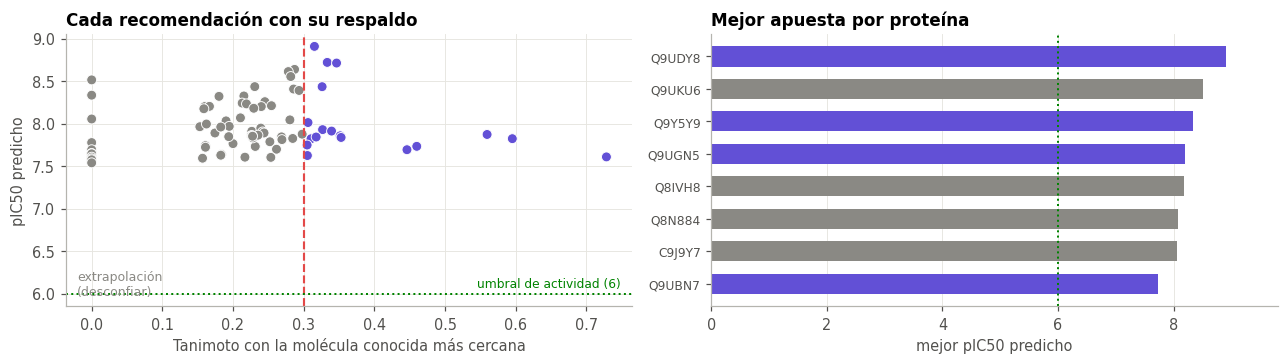

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 3.4))

ax = axes[0]
ax.scatter(REC["tanimoto_max"], REC["pIC50_pred"],
           c=np.where(REC["dentro_del_dominio"], VIOLETA, GRIS), s=42,
           edgecolors="white", linewidths=.6)
ax.axvline(TANI_MIN_CONFIABLE, color=ROJO, lw=1.4, ls="--")
ax.axhline(UMBRAL, color=VERDE, lw=1.3, ls=":")
ax.annotate("extrapolación\n(desconfiar)", xy=(.02, .04), xycoords="axes fraction",
            color=GRIS, fontsize=8.2)
ax.annotate(f"umbral de actividad ({UMBRAL:g})", xy=(.98, UMBRAL), xycoords=("axes fraction", "data"),
            xytext=(0, 4), textcoords="offset points", ha="right", color=VERDE, fontsize=8)
ax.set_xlabel("Tanimoto con la molécula conocida más cercana")
ax.set_ylabel("pIC50 predicho"); ax.set_title("Cada recomendación con su respaldo")

ax = axes[1]
pb = REC.groupby("proteína")["pIC50_pred"].max().sort_values()
cols = [VIOLETA if REC[REC["proteína"] == p]["dentro_del_dominio"].any() else GRIS
        for p in pb.index]
ax.barh(range(len(pb)), pb.to_numpy(), color=cols, height=.62)
ax.axvline(UMBRAL, color=VERDE, lw=1.3, ls=":")
ax.set_yticks(range(len(pb))); ax.set_yticklabels(pb.index, fontsize=8)
ax.set_xlim(0, max(pb.max()*1.1, UMBRAL*1.1)); ax.grid(axis="y", visible=False)
ax.set_xlabel("mejor pIC50 predicho"); ax.set_title("Mejor apuesta por proteína")
guardar(fig, "02_recomendaciones")

Top-10 propuesto para Q9UDY8 — Mucosa-associated lymphoid tissue lymphoma translocation
(ninguno de estos pares ha sido medido; 29,898 candidatos evaluados)


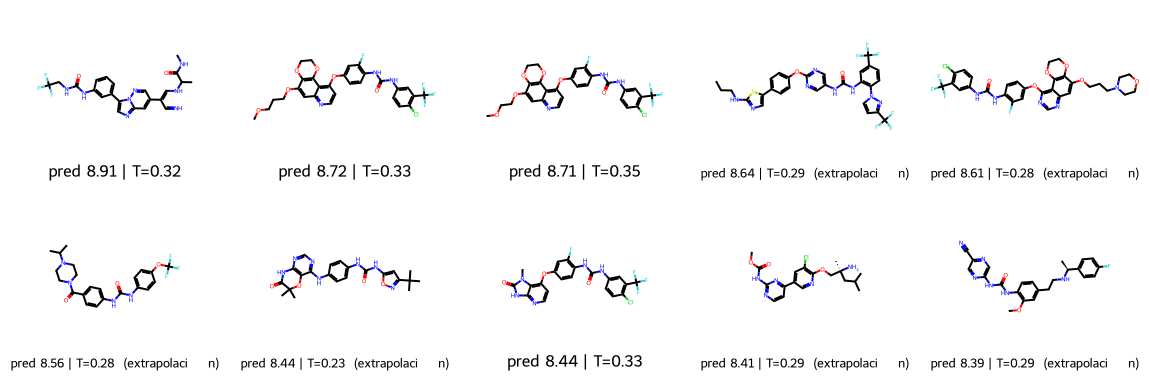

In [9]:
# Las estructuras de la mejor apuesta: esto es lo que se propondría probar
pid = REC.sort_values("pIC50_pred", ascending=False)["proteína"].iloc[0]
sub = REC[REC["proteína"] == pid].sort_values("pIC50_pred", ascending=False).head(10)
ms, lg = [], []
for _, r_ in sub.iterrows():
    smi = smi_lig.get(r_["lig_id"])
    m_ = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
    if m_ is None: continue
    ms.append(m_)
    marca = "" if r_["dentro_del_dominio"] else "  (extrapolación)"
    lg.append(f"pred {r_['pIC50_pred']:.2f} | T={r_['tanimoto_max']:.2f}{marca}")
print(f"Top-10 propuesto para {pid} — {str(nom_tgt.get(pid, ''))[:56]}")
print(f"(ninguno de estos pares ha sido medido; {sub['candidatos'].iloc[0]:,} candidatos evaluados)")
Draw.MolsToGridImage(ms, legends=lg, molsPerRow=5, subImgSize=(230, 190)) if ms else None

**Lectura.** El panel izquierdo es la forma honesta de presentar recomendaciones sobre pares no medidos: cada una lleva su respaldo. Las del cuadrante superior derecho —potencia alta estimada **y** Tanimoto alto— son las que valdría la pena llevar a un experimento; las de la izquierda son extrapolaciones y el gris lo dice.

Conviene ser explícito sobre qué significan estas tablas: el `pIC50_pred` **no es una predicción calibrada de lo que daría el ensayo**. Es una puntuación que sirve para ordenar, validada solo en términos relativos (§5 y §6). Un par del top con Tanimoto 0.7 significa *"se parece mucho a cosas que esta proteína ya une con fuerza"*, que es una hipótesis razonable, no un resultado.

**Y un hallazgo práctico sobre cómo generar candidatos.** Solo una minoría de las recomendaciones cae dentro del dominio de aplicabilidad, y la razón es el diseño del catálogo: tomar moléculas **al azar** de las 831 mil garantiza que casi ninguna se parezca a lo que una proteína concreta ya une. Para usar esto de verdad, el catálogo no debería muestrearse al azar sino construirse por **búsqueda por similitud** a partir de los compuestos activos conocidos de esa proteína — es decir, generar candidatos dentro del dominio en lugar de filtrarlos después. El muestreo aleatorio sirve aquí para mostrar el mecanismo y el filtro funcionando; no es la forma eficiente de buscar.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Conclusiones</span></div>

In [10]:
H = {
    "Celdas de la matriz": f"{CELDAS:,}",
    "Pares medidos": f"{len(I):,} ({100*len(I)/CELDAS:.4f}%)",
    "Pares SIN medir": f"{CELDAS-len(I):,}",
    "VALIDACIÓN RETROSPECTIVA": "",
    "  Entrenamiento": f"publicado hasta {CORTE:.0f} ({len(pasado):,} pares)",
    "  Evaluación": f"medido después ({len(futuro):,} pares)",
    "  Azar (prevalencia)": f"{PREV:.3f}",
    f"  precision@{TOP_K} del híbrido": f"{tabla.loc['híbrido', f'precision@{TOP_K}']:.4f}",
    "  Enriquecimiento": f"{tabla.loc['híbrido','enriquecimiento']:.3f}× de un techo de {TECHO:.3f}×",
    "  AUC": f"{tabla.loc['híbrido','auc']:.4f}",
    "PRUEBA DE DILUCIÓN": "",
    "  Dilución aplicada": f"{DILUCION} moléculas sin medir por cada candidato con verdad",
    "  Concentración de lo conocido en el top": f"{RES['dilucion_concentracion']:.1f}× el azar",
    "RECOMENDACIONES": "",
    "  Catálogo evaluado": f"{len(CATALOGO):,} moléculas × {len(PROTS)} proteínas",
    "  Dentro del dominio de aplicabilidad": f"{100*REC['dentro_del_dominio'].mean():.0f}%",
    "  Archivo": str(OUT_REC),
}
display(pd.Series(H, name="valor").to_frame())
RES["generado"] = pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")
RES["resumen"] = H
OUT_RES.write_text(json.dumps(RES, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
print(f"\nResultados en {OUT_RES}")

,valor
Celdas de la matriz,"2,861,960,556"
Pares medidos,"1,248,252 (0.0436%)"
Pares SIN medir,"2,860,712,304"
VALIDACIÓN RETROSPECTIVA,
Entrenamiento,"publicado hasta 2022 (1,040,255 pares)"
Evaluación,"medido después (107,399 pares)"
Azar (prevalencia),0.632
precision@10 del híbrido,0.7045
Enriquecimiento,1.214× de un techo de 2.320×
AUC,0.6181



Resultados en data\processed\rec_pares_nuevos.json


### Lo que se puede afirmar

1. **Recomendar pares no probados es el objetivo, y el modelo lo hace por encima del azar.** La validación retrospectiva lo demuestra sin simulaciones: se entrenó con lo publicado hasta el año de corte y ordenó correctamente pares que en ese momento nadie había medido.
2. **El orden sobrevive a la dilución.** Al mezclar los candidatos con verdad entre veinte veces más moléculas desconocidas, los ya medidos siguen concentrándose en el top muy por encima de lo esperable por azar. Si el modelo no distinguiera, los desconocidos los habrían desplazado.
3. **El modelo recomienda dentro de su dominio.** Las moléculas que sube al top tienen un parecido con lo conocido muy superior al del catálogo completo: explota vecindarios densos en lugar de extrapolar a ciegas.

### Lo que NO se puede afirmar

1. **Que un par recomendado se una de verdad.** Eso solo lo dice un experimento. Las tablas son hipótesis ordenadas, no resultados.
2. **Que la `precision@10` de la §5 se traslade a un catálogo nuevo.** Entre pares medidos el 63 % son activos porque alguien ya los filtró por criterio experto; entre pares no medidos la tasa real es muchísimo menor. **Lo que se traslada es el enriquecimiento relativo, no la precisión absoluta.**
3. **Que el `pIC50` predicho sea una estimación calibrada** del valor que daría el ensayo. Es una puntuación para ordenar; su RMSE está limitado por el ruido experimental de los propios datos.
4. **Que las recomendaciones sean química novedosa.** El modelo propone moléculas parecidas a las ya conocidas, porque es lo que el principio de similitud permite. Explota, no explora.

### Cómo se usaría en la práctica

Filtrar por `dentro_del_dominio`, ordenar por `pIC50_pred`, exigir `n_fuentes` ≥ 2 para que la sugerencia tenga más de un respaldo, y tratar el resultado como una **lista de candidatos a ensayar**, con el enriquecimiento como expectativa realista de cuántos acertarán respecto de elegir al azar.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Referencias</span></div>

1. **BindingDB.** Liu, T. *et al.* (2007). BindingDB: a web-accessible database of experimentally determined protein–ligand binding affinities. *Nucleic Acids Research*, 35, D198–D201.
2. **Huellas circulares.** Rogers, D. y Hahn, M. (2010). Extended-Connectivity Fingerprints. *Journal of Chemical Information and Modeling*, 50(5), 742–754.
3. **Principio de similitud.** Johnson, M. A. y Maggiora, G. M. (1990). *Concepts and Applications of Molecular Similarity*. Wiley.
4. **Dominio de aplicabilidad.** Tropsha, A., Gramatica, P. y Gombar, V. K. (2003). The Importance of Being Earnest: Validation is the Absolute Essential for Successful Application and Interpretation of QSPR Models. *QSAR & Combinatorial Science*, 22(1), 69–77.
5. **Cribado virtual y enriquecimiento.** Truchon, J.-F. y Bayly, C. I. (2007). Evaluating Virtual Screening Methods. *Journal of Chemical Information and Modeling*, 47(2), 488–508.
6. **Recomendación híbrida.** Burke, R. (2002). Hybrid Recommender Systems: Survey and Experiments. *User Modeling and User-Adapted Interaction*, 12(4), 331–370.
7. **RDKit.** Landrum, G. *RDKit: Open-source cheminformatics.* https://www.rdkit.org